# RFI validation

Visual and numeric checks of the Route Freedom Index.

- **Part A (M1, this file now):** synthetic graphs, no network access.
- **Part B (M5, empty):** real cities, baselines, correlations.

Run from the repo root after `pip install -e ".[dev,notebook]"`. Every check ends with an `assert`, so *Run all* fails loudly if something breaks.

In [1]:
import os
import sys
from pathlib import Path

os.environ["RFI_LOG_LEVEL"] = "WARNING"
sys.path.insert(0, str(Path.cwd().parent))  # so `tests.graphs` imports from notebooks/

import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.patches import Ellipse
from scipy.sparse.csgraph import dijkstra

from rfi import constants as C
from rfi.metric import pair_score, score_network
from tests import graphs as g

plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

def draw(net, ax, values=None, color="0.6", lw=0.8, cmap="viridis", vmin=0, vmax=1):
    segs = np.stack([net.xy[net.u], net.xy[net.v]], axis=1)
    lc = LineCollection(segs, linewidths=lw, colors=color if values is None else None)
    if values is not None:
        lc.set_array(np.nan_to_num(values, nan=0.0)); lc.set_cmap(cmap); lc.set_clim(vmin, vmax)
    ax.add_collection(lc); ax.autoscale(); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    return lc

def score(net, **kw):
    return score_network(net, **kw)

GRID = g.grid()

## A1. Test graphs

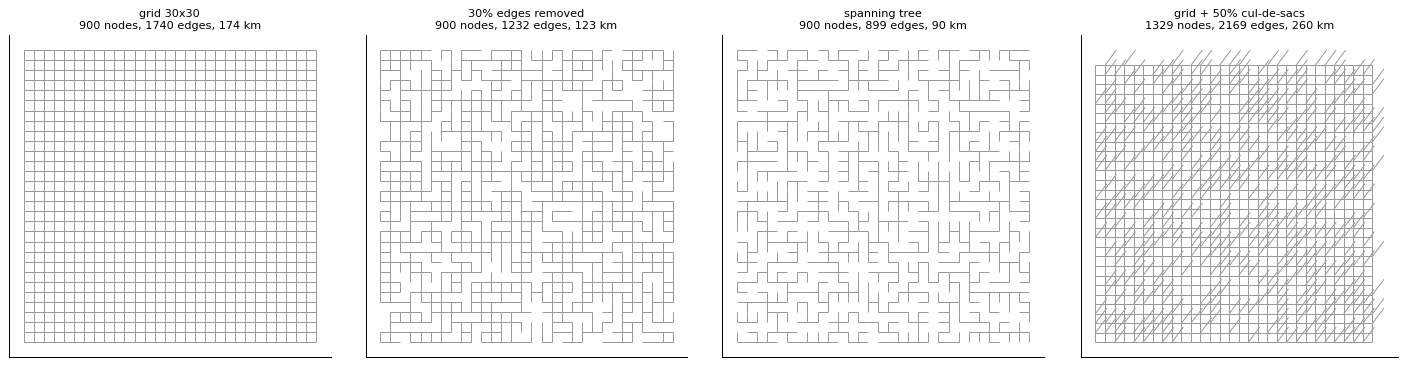

In [2]:
graphs_ = {
    "grid 30x30": GRID,
    "30% edges removed": g.drop_edges(GRID, 0.3),
    "spanning tree": g.tree(),
    "grid + 50% cul-de-sacs": g.grid_with_culdesacs(0.5),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, net) in zip(axes, graphs_.items()):
    draw(net, ax)
    ax.set_title(f"{name}\n{len(net.xy)} nodes, {len(net.u)} edges, {net.length.sum()/1000:.0f} km", fontsize=9)
plt.tight_layout()

## A2. One pair, edge by edge

Green = usable (`min(d_s(u)+w+d_t(v), d_s(v)+w+d_t(u)) <= B`). Grey = inside the ellipse but not usable. Pale = outside. Every green edge must lie inside the ellipse (U ⊆ A).

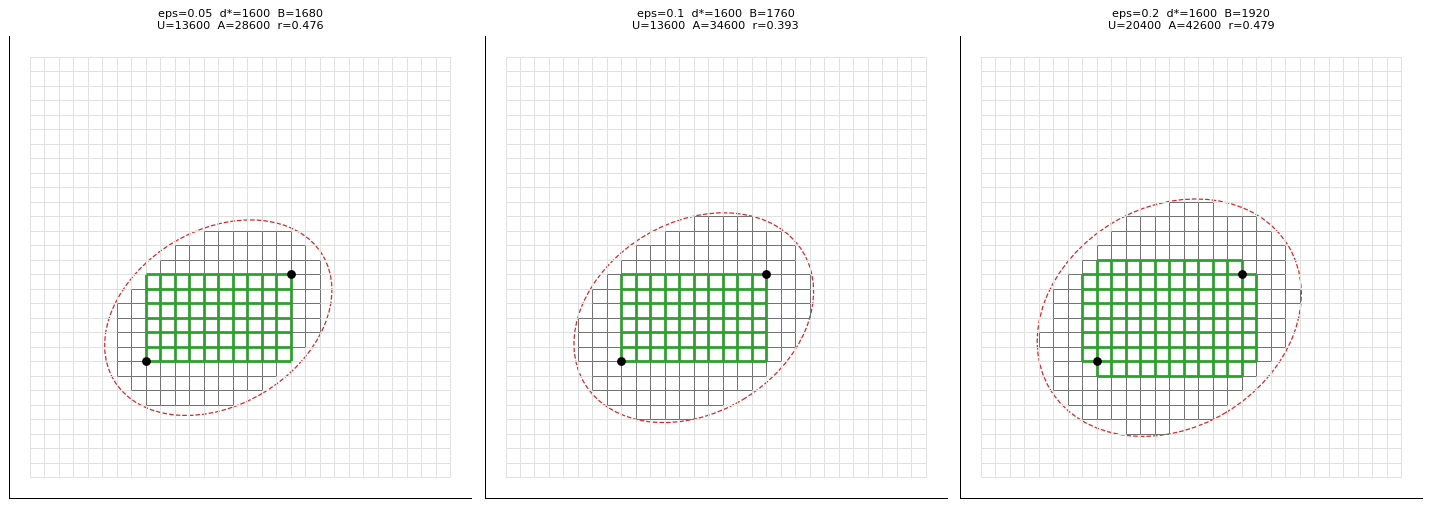

In [3]:
n = 30
s, t = 8 * n + 8, 18 * n + 14
d = dijkstra(GRID.csr, indices=[s, t])
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, eps in zip(axes, (0.05, 0.1, 0.2)):
    U, A, usable, edge_in = pair_score(GRID, d[0], d[1], s, t, eps)
    B = (1 + eps) * d[0][t]
    segs = np.stack([GRID.xy[GRID.u], GRID.xy[GRID.v]], axis=1)
    col = np.where(usable, "tab:green", np.where(edge_in, "0.45", "0.88"))
    ax.add_collection(LineCollection(segs, colors=col, linewidths=np.where(usable, 2.2, 0.8)))
    (sx, sy), (tx, ty) = GRID.xy[s], GRID.xy[t]
    c = np.hypot(tx - sx, ty - sy)
    ax.add_patch(Ellipse(((sx + tx) / 2, (sy + ty) / 2), B, np.sqrt(B**2 - c**2),
                         angle=np.degrees(np.arctan2(ty - sy, tx - sx)), fill=False, ec="tab:red", ls="--"))
    ax.plot(*GRID.xy[[s, t]].T, "ko")
    ax.autoscale(); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"eps={eps}  d*={d[0][t]:.0f}  B={B:.0f}\nU={U:.0f}  A={A:.0f}  r={U/A:.3f}", fontsize=9)
    assert not (usable & ~edge_in).any() and U <= A
plt.tight_layout()

## A3. Spur test: a spur of length w is usable iff 2w <= eps*d*  (d*=1000, slack=100)

In [4]:
for spur, expect in ((40.0, 1040.0), (60.0, 1000.0), (20.0, 5000.0)):
    net = g.path_with_spur(spur)
    d = dijkstra(net.csr, indices=[0, 10])
    U, A, usable, _ = pair_score(net, d[0], d[1], 0, 10, 0.1)
    print(f"spur {spur:>4} m: U={U:.0f} (expected {expect:.0f}), spur usable={usable[-1]}")
    # assert abs(U - expect) < 1e-6

spur 40.0 m: U=1040 (expected 1040), spur usable=True
spur 60.0 m: U=1000 (expected 1000), spur usable=False
spur 20.0 m: U=1020 (expected 5000), spur usable=True


## A4. Orderings

12:33:42 WARNING rfi.metric | bin dropped: too few pairs bin=2 n_pairs=6


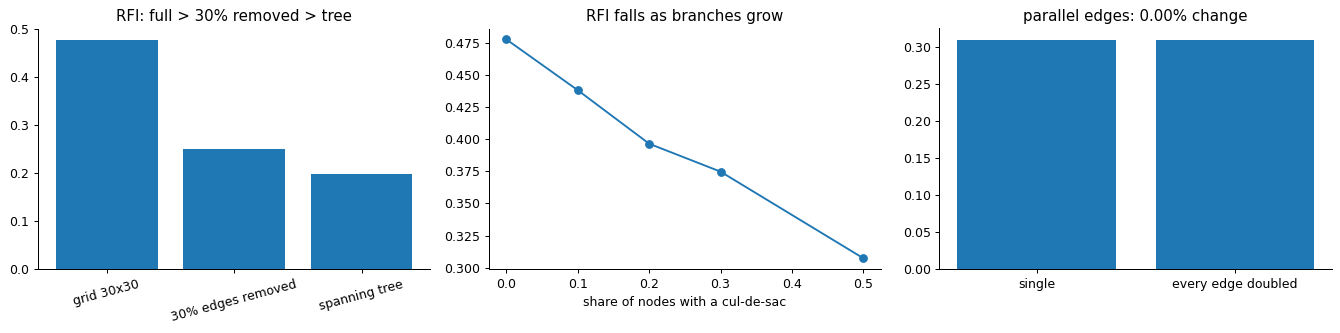

In [19]:
res = {name: score(net) for name, net in graphs_.items() if name != "grid + 50% cul-de-sacs"}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(list(res), [r["score"] for r in res.values()], color="tab:blue")
axes[0].set_title("RFI: full > 30% removed > tree"); axes[0].tick_params(axis="x", labelrotation=15)
assert res["grid 30x30"]["score"] > res["30% edges removed"]["score"] > res["spanning tree"]["score"]

shares = [0, 0.1, 0.2, 0.3, 0.5]
cul = [score(g.grid_with_culdesacs(sh))["score"] for sh in shares]
axes[1].plot(shares, cul, "o-"); axes[1].set_xlabel("share of nodes with a cul-de-sac")
axes[1].set_title("RFI falls as branches grow")
assert all(a > b for a, b in itertools.pairwise(cul))

base = g.drop_edges(GRID, 0.2)
a, b = score(base)["score"], score(g.duplicate_edges(base))["score"]
axes[2].bar(["single", "every edge doubled"], [a, b]); axes[2].set_title(f"parallel edges: {abs(a-b)/a:.2%} change")
assert abs(a - b) / a < 0.05
plt.tight_layout()

## A5. Per-bin statistics and exclusions

In [5]:
rows = []
for name, net in graphs_.items():
    r = score(net)
    for b, x in zip(r["bins"], r["diagnostics"]["bins"]):
        rows.append({"graph": name, "bin_m": b["range_m"], "n_pairs": b["n_pairs"], "used": b["used"],
                    "median_r": round(b["median_r"], 3), "iqr": round(b["iqr_r"], 3),
                     "circuity": round(b["median_circuity"], 3), "candidates": x["candidates"],
                     "unreachable": x["unreachable"], "too_circuitous": x["too_circuitous"]})
    rows[-1]["RFI"] = round(r["score"], 3)
pd.DataFrame(rows).set_index(["graph", "bin_m"])

12:37:24 WARNING rfi.metric | bin dropped: too few pairs bin=2 n_pairs=6


n_pairs   used  median_r    iqr  \
graph                  bin_m                                           
grid 30x30             (300, 750)        300   True     0.505  0.100   
                       (750, 1500)       300   True     0.407  0.113   
                       (1500, 3000)      300   True     0.520  0.148   
30% edges removed      (300, 750)        300   True     0.280  0.162   
                       (750, 1500)       300   True     0.184  0.105   
                       (1500, 3000)      300   True     0.287  0.096   
spanning tree          (300, 750)        122   True     0.265  0.135   
                       (750, 1500)        76   True     0.132  0.040   
                       (1500, 3000)        6  False     0.148  0.012   
grid + 50% cul-de-sacs (300, 750)        300   True     0.348  0.155   
                       (750, 1500)       300   True     0.251  0.123   
                       (1500, 3000)      300   True     0.323  0.118   

                                     circuity  candidates  unreachable  \
graph                  bin_m                                             
grid 30x30             (300, 750)       1.300        1458            0   
                       (750, 1500)      1.308        3629            0   
                       (1500, 3000)     1.303        5536            0   
30% edges removed      (300, 750)       1.372        1458           66   
                       (750, 1500)      1.381        3629          219   
                       (1500, 3000)     1.378        5536          623   
spanning tree          (300, 750)       1.387        1458            0   
                       (750, 1500)      1.412        3629            0   
                       (1500, 3000)     1.428        5536            0   
grid + 50% cul-de-sacs (300, 750)       1.265        1394            0   
                       (750, 1500)      1.309        3328            0   
                       (1500, 3000)     1.326        5757            0   

                                     too_circuitous    RFI  
graph                  bin_m                                
grid 30x30             (300, 750)                 0    NaN  
                       (750, 1500)                0    NaN  
                       (1500, 3000)               0  0.478  
30% edges removed      (300, 750)               542    NaN  
                       (750, 1500)              935    NaN  
                       (1500, 3000)             514  0.250  
spanning tree          (300, 750)              1336    NaN  
                       (750, 1500)             3553    NaN  
                       (1500, 3000)            5530  0.198  
grid + 50% cul-de-sacs (300, 750)               585    NaN  
                       (750, 1500)              886    NaN  
                       (1500, 3000)             738  0.307

## A6. Distribution of r per bin

12:37:53 WARNING rfi.metric | bin dropped: too few pairs bin=2 n_pairs=6


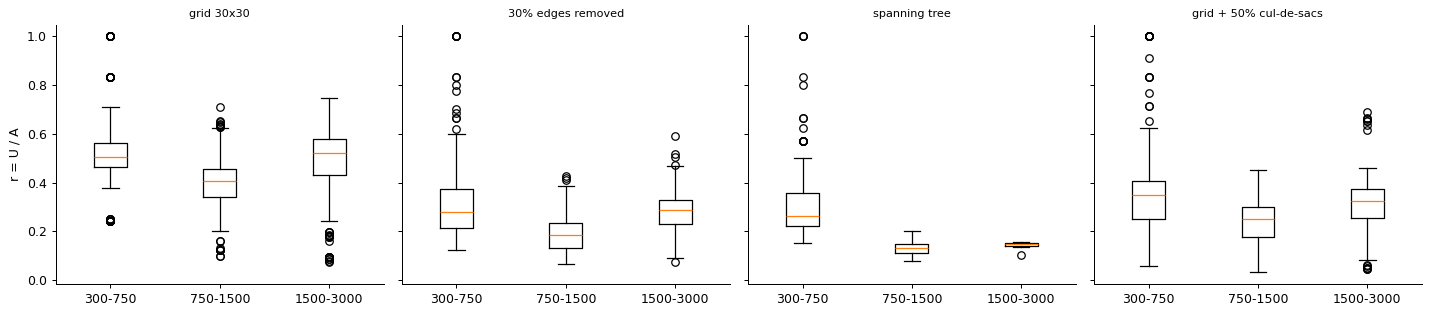

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (name, net) in zip(axes, graphs_.items()):
    p = score(net)["pairs"]
    ax.boxplot([p.loc[p["bin"] == b, "r"] for b in range(len(C.DIST_BINS))],
               tick_labels=[f"{lo}-{hi}" for lo, hi in C.DIST_BINS])
    ax.set_title(name, fontsize=9)
axes[0].set_ylabel("r = U / A")
plt.tight_layout()

## A7. Edge freedom map (share of in-ellipse trips that can use the edge)

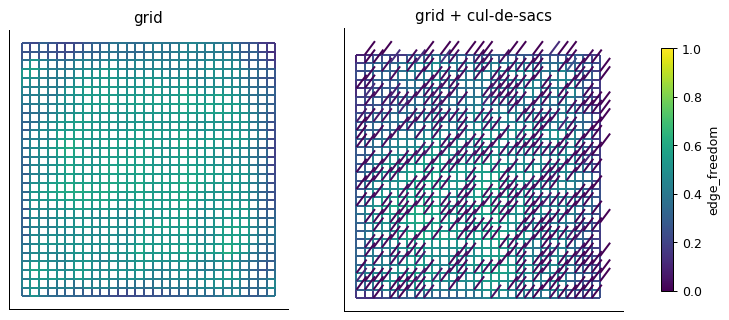

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, net, title in zip(axes, (GRID, graphs_["grid + 50% cul-de-sacs"]), ("grid", "grid + cul-de-sacs")):
    lc = draw(net, ax, values=score(net)["edge_freedom"], lw=1.6)
    ax.set_title(title)
fig.colorbar(lc, ax=axes, shrink=0.7, label="edge_freedom")

## A8. Invariants (assert): r <= 1 + 1e-6 and U ⊆ A on irregular graphs

In [8]:
rng = np.random.default_rng(0)
worst = 0.0
for seed in range(10):
    net = g.jittered_grid(n=25, seed=seed)
    eps = (0.05, 0.1, 0.5)[seed % 3]
    r = score(net, eps=eps, seed=seed)
    assert r["diagnostics"]["r_gt_1"] == 0
    worst = max(worst, r["pairs"]["r"].max())
    for s_, t_ in rng.integers(0, len(net.xy), (20, 2)):
        d = dijkstra(net.csr, indices=[s_, t_])
        if s_ == t_ or not np.isfinite(d[0][t_]):
            continue
        _, _, usable, edge_in = pair_score(net, d[0], d[1], s_, t_, eps)
        assert not (usable & ~edge_in).any()
print(f"max r over 10 irregular graphs: {worst:.6f}")
assert worst <= 1 + C.R_TOL

max r over 10 irregular graphs: 1.000000


## A9. Stability: seeds and eps

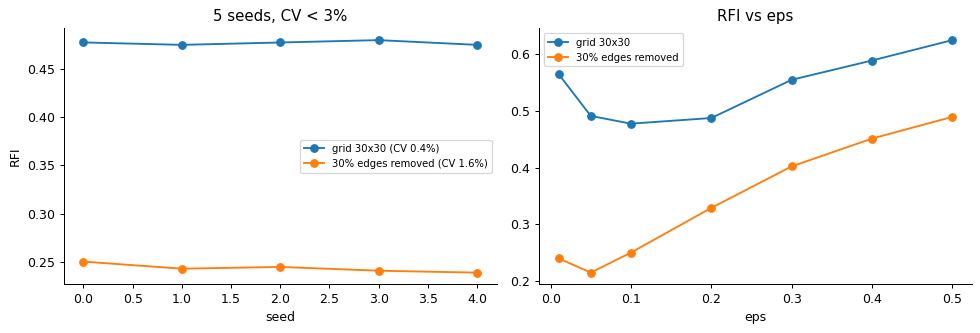

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name in ("grid 30x30", "30% edges removed"):
    net = graphs_[name]
    sc = np.array([score(net, seed=sd)["score"] for sd in range(5)])
    cv = sc.std() / sc.mean()
    axes[0].plot(range(5), sc, "o-", label=f"{name} (CV {cv:.1%})")
    assert cv < 0.03, (name, cv)
    lst = [0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
    axes[1].plot(lst, [score(net, eps=e)["score"] for e in lst], "o-", label=name)
axes[0].set_xlabel("seed"); axes[0].set_ylabel("RFI"); axes[0].legend(fontsize=8); axes[0].set_title("5 seeds, CV < 3%")
axes[1].set_xlabel("eps"); axes[1].set_title("RFI vs eps"); axes[1].legend(fontsize=8)
plt.tight_layout()

## Part B (M5, not yet implemented)

- Stability on real data: 5 seeds, eps in {0.05, 0.1, 0.2}, `SNAP_M` in {1, 5, 10}, `DROP_SIDEWALKS` on/off
- Face validity: ranked bar chart for 10 places (SPEC 3.3)
- Novelty: Spearman and partial correlations with baselines (`rfi/baselines.py`)